# LangGraph Fundamentals: Building a ReAct Agent

The pattern we're implementing is called **ReAct** (Reason + Act). The agent runs a cycle:

1. **Reason** — the LLM looks at the conversation so far and decides what to do next.
2. **Act** — if the LLM decided to use a tool, plain Python code executes that tool.
3. **Observe** — the tool's result is appended to the conversation, and we go back to step 1.

The loop repeats until the LLM decides it has enough information to answer in plain text. A chain can't express this, because you don't know in advance how many tool calls a given request will need. A graph can — edges are allowed to point backwards.

One fact to hold onto throughout, because everything else follows from it:

> **The LLM never executes anything.** It only emits a structured *request* to call a tool. Our own code executes the function and feeds the result back. The "agent" is the LLM plus this surrounding loop, working together.

### What we'll build

A time-off assistant that can check a leave balance, book leave, and — when it's missing information — pause the entire program and ask the human. Along the way:

1. **Tools** — Python functions the LLM can request
2. **State** — the shared data structure every step reads and writes
3. **Nodes** — the reason step and the act step
4. **Edges** — the routing logic that creates the loop
5. **Human-in-the-loop** — pausing execution with `interrupt()`
6. **Persistence** — checkpointers, and why pausing requires saving

![Diagram](./images/01_img.png)

In [1]:
from langchain.messages import SystemMessage, ToolMessage, HumanMessage, AIMessage
from dotenv import load_dotenv
import os

In [2]:
# os.environ["LANGSMITH_TRACING"] = "true" # false for no tracing
# os.environ["LANGSMITH_PROJECT"] = "Langgraph-Workshop"
load_dotenv(override=True) # .env values take precedence over existing shell env vars

True

![Diagram](./images/00_img.png)

## 1) Defining Tools

A tool is an ordinary Python function plus enough metadata for the LLM to know it exists and how to call it. The `@tool` decorator extracts that metadata — the function name, the type hints, and crucially the **docstring** — and packages it into a schema that gets sent to the model along with every request.

The docstring is not a comment here; it's effectively part of the prompt. When the model decides whether and how to call `process_time_off`, the description of `start_date` ("a date string in YYYY-MM-DD format") is what it's working from. Vague docstrings produce wrong arguments.

We define two tools:
* `get_time_off_balance` — **reads** data
* `process_time_off` — **writes** data (books the leave)

**Be aware these are stubs.** `get_time_off_balance` always returns `10`, so when the agent later reports "your remaining balance is 9," nothing was actually decremented — book leave twice in a row and the balance resets. In a real system these two functions would hit a database; everything else in this notebook would stay exactly the same. That separation — the agent machinery doesn't care what's behind a tool — is part of the point.

📚 **[Docs: LangChain Tools](https://docs.langchain.com/oss/python/langchain/tools)**

![Diagram](./images/02_img.png)

In [4]:
from datetime import datetime
from langchain.tools import tool

In [5]:
@tool
def get_time_off_balance(user_id: str) -> int:
    '''
    Get the time off balance for a user. 

    Args :
        user_id: A unique string representing the user id

    Returns:
        An integer value representing the time-off balance
    '''
    return 10

@tool
def process_time_off(user_id: str, start_date: str, end_date: str) -> dict:
    '''
    Process time-off request for a user

    Args :
        user_id: A unique string representing the user id
        start_date: A date string in YYYY-MM-DD format for the start date of the time-off request
        end_date: A date string in YYYY-MM-DD format for the end date of the time-off request

    Returns:
        A dictionary with the following keys:
        - status: A string value representing the status of the time-off request
        - message: A string value representing the message of the time-off request
    '''
    start_date = datetime.strptime(start_date, "%Y-%m-%d")
    end_date = datetime.strptime(end_date, "%Y-%m-%d")

    days_requested = end_date - start_date
    time_off_balance = get_time_off_balance.invoke({"user_id": user_id})

    result = {}

    if days_requested.days + 1 > time_off_balance:
        result['status'] = 'error'
        result['message'] = f'Time off request failed. you only have {time_off_balance} days of remaining leaves but requested {days_requested.days} days'

    else:
        time_off_balance -= days_requested.days + 1
        result['status'] = 'success'
        result['message'] = f'Time off request processed successfully for {days_requested.days + 1} days. Your remaining time off balance is {time_off_balance}'


    return result


## 2) Graph State

State is the single data structure that flows through the graph. Every node receives the current state, does its work, and returns *only the fields it wants to update* — LangGraph merges that update into the state before the next node runs.

Our state has two fields:
* `chat_history` — the full message list: human messages, AI responses, tool results
* `user_id` — who we're acting on behalf of

The interesting part is `Annotated[list[AnyMessage], add_messages]`. That second argument is a **reducer**: it tells LangGraph *how* to merge a node's update into the existing value.

* **Without a reducer** (like `user_id` here), an update **replaces** the field — last write wins.
* **With `add_messages`**, a node that returns one new message gets it **appended** to the existing history instead of wiping it.

Why `add_messages` rather than plain list concatenation (`operator.add` would also append)? Because `add_messages` is message-aware: it tracks message IDs, so if the same message flows through twice — which genuinely happens when execution is resumed after an interrupt, as we'll see in section 8 — it deduplicates instead of double-appending. For message lists, this is the reducer you want essentially always.

📚 **[Docs: State Management](https://langchain-ai.github.io/langgraph/concepts/low_level/#state)**

![Diagram](./images/03_img.png)

In [6]:
from typing import Annotated, TypedDict, Optional
from langchain.messages import AnyMessage
from langgraph.graph import add_messages

In [7]:
class GraphState(TypedDict):
    chat_history: Annotated[list[AnyMessage], add_messages]
    user_id: Optional[str]

## 3) Nodes

A node is just a function: state in, partial state update out. Our agent needs exactly two — one for each half of the ReAct loop.

**`reason_node` — the thinking step.** It assembles a prompt (system message + chat history) and invokes the LLM. The response is an `AIMessage` containing either plain text (a final answer) or a `tool_calls` list (a request to act). Either way, the node just appends it to `chat_history` — deciding what happens *next* is the router's job (section 4), not this node's.

**`action_node` — the doing step.** It reads the `tool_calls` from the last message, looks up each requested tool by name in `tools_by_name`, executes it with the arguments the model provided, and appends each result as a `ToolMessage`. This is the plain-Python half of the loop — no LLM involved.

Two details worth noticing in the code:

* `llm.bind_tools(tools)` happens **once, at module level** — not inside the node. Binding attaches the tool schemas to every request the model will see; `reason_node` just invokes the already-bound model.
* The system prompt is imported from [langraph_prompts.py](langraph_prompts.py). It's short, and worth reading because it's half of the agent's behavior:

```text
You are a helpful and accurate employee Time-Off Assistant.
You are given a user's request, and you need to reason about the user's
query and call the necessary tools to answer the user's query.

today's date : {todays_date}
user_id : {user_id}
```

That `{todays_date}` injection matters more than it looks: it's the only reason the model can resolve "I want leave **tomorrow**" into a concrete `YYYY-MM-DD` date for the tool call. Remove it and the agent has no idea what day it is.

![Diagram](./images/04_img.png)

In [8]:
from langchain.chat_models import init_chat_model
from langraph_prompts import ACTION_PROMPT_TEMPLATE

llm = init_chat_model(model="gpt-4o", temperature=0)
tools = [get_time_off_balance, process_time_off]
tools_by_name = {tool.name : tool for tool in tools}
llm_with_tools = llm.bind_tools(tools)

def reason_node(state: GraphState):

    system_message = SystemMessage(
        ACTION_PROMPT_TEMPLATE.format(
            todays_date=datetime.now().strftime("%Y-%m-%d"),
            user_id=state['user_id'],
        )
    )

    llm_response = llm_with_tools.invoke([system_message] + state['chat_history'])

    return {
            'chat_history': [llm_response]
        }

def action_node(state: GraphState):

    result = []

    for tool_call in state['chat_history'][-1].tool_calls:
            tool = tools_by_name[tool_call["name"]]
            observation = tool.invoke(tool_call["args"])
            result.append(ToolMessage(content= str(observation), tool_call_id=tool_call["id"]))

    return {
        'chat_history': result
    }


## 4) Edges: Wiring the Loop

Nodes define what the agent *can* do; edges define what happens *next*. This is where the ReAct loop actually gets built.

There are two kinds of edges:

* **Fixed edges** (`add_edge`) always go from A to B. `action_node → reason_node` is fixed: after running tools, we always go back to think about the results.
* **Conditional edges** (`add_conditional_edges`) call a function that inspects the state and returns the name of the next node. Our `conditional_router` checks the last message: if it contains `tool_calls`, the model wants to act → route to `action_node`. If not, the model produced a final answer → route to `END`.

The full shape:

```text
START → reason_node ──(tool_calls?)──→ action_node ──→ back to reason_node
                    └─(no tool_calls)─→ END
```

That back-edge from `action_node` to `reason_node` is the entire reason we need a graph instead of a chain — it's what lets the agent take as many tool-using turns as the request requires.

`graph.compile()` turns the blueprint into a runnable agent. The output below is the compiled graph drawing itself — the dashed lines are the conditional routes.

![Diagram](./images/05_img.png)

In [9]:
from langgraph.graph import StateGraph, END, START

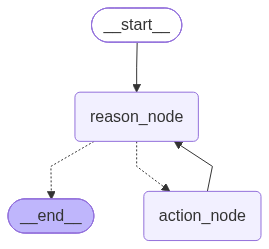

In [10]:
graph = StateGraph(GraphState)

graph.add_node('reason_node', reason_node)
graph.add_node('action_node', action_node)


def conditional_router(state: GraphState):
    if state['chat_history'][-1].tool_calls:
        return 'action_node'
    return END

graph.add_edge(START, 'reason_node')
graph.add_conditional_edges('reason_node', conditional_router, ['action_node', END])
graph.add_edge('action_node', 'reason_node')


agent = graph.compile()

agent

In [11]:
user_id = '1' 
user_message = "I want to take leave tomorrow"

## 5) Running the Agent and Reading the Trace

`agent.stream(..., stream_mode="updates")` yields one chunk per node execution, which lets us watch the loop turn in real time. The printing code below just sorts each message by what it is:

* an `AIMessage` with `tool_calls` → the model is **requesting** an action
* a `ToolMessage` → the **result** of an executed tool
* an `AIMessage` with `content` → the **final answer**

**Read the trace below as laps around the loop.** For "I want to take leave tomorrow," the agent makes two full trips:

1. *Reason* → calls `get_time_off_balance` → *Act* → observes `10`
2. *Reason* → calls `process_time_off` with concrete dates → *Act* → observes success
3. *Reason* → nothing left to do → answers in plain text → `END`

Nobody told it to take two trips. That count emerged from the model's own decisions — which is exactly the behavior a fixed chain can't produce. Also notice the dates in the second tool call: the model converted "tomorrow" into a real date using the `todays_date` we injected into the system prompt.

In [12]:
print("=" * 80)
print("🚀 Starting Agent Execution")
print("=" * 80)

for chunk in agent.stream({ 'user_id': user_id, 'chat_history' : [HumanMessage(content = user_message)] }, stream_mode="updates"):
    
    # Extract node name and data from chunk
    for node_name, node_data in chunk.items():
        print(f"\n{'─' * 80}")
        print(f"📍 Node: {node_name}")

        print(f"{'─' * 80}")
        
        # Check if there are messages in the chat_history
        if 'chat_history' in node_data:
            messages = node_data['chat_history']
            
            for msg in messages:
                # Handle AIMessage with tool calls
                if hasattr(msg, 'tool_calls') and msg.tool_calls:
                    print(f"\n🤖 AI is calling tools:")
                    for tool_call in msg.tool_calls:
                        print(f"   • Tool: {tool_call['name']}")
                        print(f"   • Args: {tool_call['args']}")
                
                # Handle ToolMessage (results from tools)
                elif isinstance(msg, ToolMessage):
                    print(f"\n🔧 Tool Result:")
                    print(f"   {msg.content}")
                
                # Handle AIMessage with content (final response)
                elif hasattr(msg, 'content') and msg.content:
                    print(f"\n💬 AI Response:")
                    print(f"   {msg.content}")

print(f"\n{'=' * 80}")
print("✅ Agent Execution Complete")
print("=" * 80)

🚀 Starting Agent Execution

────────────────────────────────────────────────────────────────────────────────
📍 Node: reason_node
────────────────────────────────────────────────────────────────────────────────

🤖 AI is calling tools:
   • Tool: get_time_off_balance
   • Args: {'user_id': '1'}
   • Tool: process_time_off
   • Args: {'user_id': '1', 'start_date': '2026-10-18', 'end_date': '2026-10-18'}

────────────────────────────────────────────────────────────────────────────────
📍 Node: action_node
────────────────────────────────────────────────────────────────────────────────

🔧 Tool Result:
   10

🔧 Tool Result:
   {'status': 'success', 'message': 'Time off request processed successfully for 1 days. Your remaining time off balance is 9'}

────────────────────────────────────────────────────────────────────────────────
📍 Node: reason_node
────────────────────────────────────────────────────────────────────────────────

💬 AI Response:
   Your time-off request for tomorrow, October 1

## 6) Human-in-the-Loop (Interrupts)

What should the agent do when the user says "I want to take leave" with no dates? It has three options: guess (bad), fail (worse), or **stop and ask**. LangGraph's `interrupt()` enables the third.

Calling `interrupt(message)` inside a node does something unusual: it suspends the **entire graph** at that exact line. The message is surfaced to whoever is running the graph, the program is free to exit completely, and — whenever you have an answer, seconds or days later — execution resumes from that point, with your answer becoming the *return value* of the `interrupt()` call.

For that resume to work, the graph's state has to survive the pause. That's why interrupts require a **checkpointer**, which we'll add in section 7: no saved state, no resume.

📚 **[Docs: Interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts)**

In [13]:
from langgraph.types import interrupt

![Diagram](./images/06_img.png)

## 6.1) The "Ask a Human" Tool

There's a design decision here worth pausing on: we expose the interrupt **as a tool** (`get_additional_info_from_human`) rather than hard-coding a pause at some fixed point in the graph. That means the *LLM* decides when it's stuck. We don't have to anticipate every situation that needs clarification — missing dates, ambiguous requests, anything — the model calls this tool whenever it determines it can't proceed, guided by the docstring like any other tool.

What actually happens when this tool runs (the code comments below restate this):

* Execution suspends at the `interrupt(message)` line, and the current state is saved via the checkpointer.
* The message surfaces to the caller under an `__interrupt__` key in the stream.
* The graph waits indefinitely until you resume it with a response.
* Your response becomes the return value of `interrupt()`, and the tool returns it to the agent as if it were any other tool result.

One detail to note for later: the tool body reads `interrupt_result['user_message']`. That's a contract with the resume side — whoever resumes the graph must pass a dict with a `user_message` key. We'll see the other half of that contract in section 8.

(The first two tools below are unchanged from section 1 — they're repeated only so this half of the notebook is self-contained.)

![Diagram](./images/07_img.png)

In [15]:
# tools: 

@tool
def get_time_off_balance(user_id: str) -> int:
    '''
    Get the time off balance for a user. 

    Args :
        user_id: A unique string representing the user id

    Returns:
        An integer value representing the time-off balance
    '''
    return 10

@tool
def process_time_off(user_id: str, start_date: str, end_date: str) -> dict:
    '''
    Process time-off request for a user

    Args :
        user_id: A unique string representing the user id
        start_date: A date string in YYYY-MM-DD format for the start date of the time-off request
        end_date: A date string in YYYY-MM-DD format for the end date of the time-off request

    Returns:
        A dictionary with the following keys:
        - status: A string value representing the status of the time-off request
        - message: A string value representing the message of the time-off request
    '''
    start_date = datetime.strptime(start_date, "%Y-%m-%d")
    end_date = datetime.strptime(end_date, "%Y-%m-%d")

    days_requested = end_date - start_date
    time_off_balance = get_time_off_balance.invoke({"user_id": user_id})

    result = {}

    if days_requested.days + 1 > time_off_balance:
        result['status'] = 'error'
        result['message'] = f'Time off request failed. you only have {time_off_balance} days of remaining leaves but requested {days_requested.days} days'

    else:
        time_off_balance -= days_requested.days + 1
        result['status'] = 'success'
        result['message'] = f'Time off request processed successfully for {days_requested.days + 1} days. Your remaining time off balance is {time_off_balance}'


    return result


@tool
def get_additional_info_from_human( message: str) -> str:
    '''
        Raises an interrupt to fetch additional information from the human requesting the action

        Args:
            message: a message string from the AI requesting the user for missing information

        Returns:
            A string value representing the response with additional information from the human

    '''
    interrupt_result = interrupt(message)

    return interrupt_result['user_message']




# Graph execution gets suspended at the exact point where interrupt is called
# State is saved using the checkpointer so execution can be resumed later, In production, this should be a persistent checkpointer (e.g. backed by a database)
# Value is returned to the caller under __interrupt__; it can be any JSON-serializable value (string, object, array, etc.)
# Graph waits indefinitely until you resume execution with a response
# Response is passed back into the node when you resume, becoming the return value of the interrupt() call




In [16]:
# Key points about resuming:
# You must use the same thread ID when resuming that was used when the interrupt occurred
# The value passed to Command(resume=...) becomes the return value of the interrupt call
# The node restarts from the beginning of the node where the interrupt was called when resumed, so any code before the interrupt runs again
# You can pass any JSON-serializable value as the resume value

## 6.2) Rebuilding the Nodes

This cell re-declares the model, tools, and both nodes — but **the only real change is one item in the tools list**: `get_additional_info_from_human` is now included, so `bind_tools` advertises it to the model. `reason_node` and `action_node` are identical to section 3, repeated only to keep this half of the notebook self-contained.

Nothing about the loop's structure changes. From the graph's point of view, asking a human is just another tool call — it goes through the same `action_node`, and the human's answer comes back as an ordinary `ToolMessage`.

In [16]:
# nodes

llm = init_chat_model(model="gpt-4o", temperature=0)
tools = [get_time_off_balance, process_time_off, get_additional_info_from_human ]
tools_by_name = {tool.name : tool for tool in tools}
llm_with_tools = llm.bind_tools(tools)

def reason_node(state: GraphState):

    system_message = SystemMessage(
        ACTION_PROMPT_TEMPLATE.format(
            todays_date=datetime.now().strftime("%Y-%m-%d"),
            user_id=state['user_id'],
        )
    )

    llm_response = llm_with_tools.invoke([system_message] + state['chat_history'])

    return {
            'chat_history': [llm_response]
        }

def action_node(state: GraphState):

    result = []

    for tool_call in state['chat_history'][-1].tool_calls:
            tool = tools_by_name[tool_call["name"]]
            observation = tool.invoke(tool_call["args"])
            result.append(ToolMessage(content= str(observation), tool_call_id=tool_call["id"]))

    return {
        'chat_history': result
    }

## 7) Compiling with a Checkpointer

A **checkpointer** saves a snapshot of the graph's state after every step. Compile with one, and the graph can be paused, resumed, inspected, or replayed — which is exactly what interrupts need.

Snapshots are keyed by a `thread_id` that you supply at invocation time. One thread = one conversation; a single checkpointer can hold many threads at once.

The graph definition below is unchanged from section 4 — same nodes, same edges, same router. The only differences are the updated nodes (with the human tool) and one new argument: `graph.compile(checkpointer=checkpointer)`.

`InMemorySaver` keeps everything in RAM — perfect for a notebook, gone when the kernel restarts. In production you'd swap in a database-backed checkpointer (Postgres, Redis, SQLite), and **nothing else in the code changes** — the checkpointer is the only line you'd touch.

📚 **[Docs: Persistence](https://langchain-ai.github.io/langgraph/concepts/persistence/)**

![Diagram](./images/08_img.png)

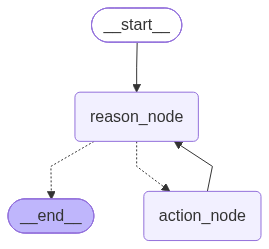

In [17]:
# Compile graph
from langgraph.checkpoint.memory import InMemorySaver

graph = StateGraph(GraphState)

graph.add_node('reason_node', reason_node)
graph.add_node('action_node', action_node)


def conditional_router(state: GraphState):
    if state['chat_history'][-1].tool_calls:
        return 'action_node'
    return END

graph.add_edge(START, 'reason_node')
graph.add_conditional_edges('reason_node', conditional_router, ['action_node', END])
graph.add_edge('action_node', 'reason_node')

checkpointer = InMemorySaver()
agent = graph.compile(checkpointer=checkpointer)

agent

## 8) Running with Interrupts

The driver below adds one mechanism to the run loop from section 5: it watches for an `__interrupt__` key in the stream. When that key appears, the graph has paused — we collect input from the human, then call `agent.stream()` again, but this time passing `Command(resume={'user_message': ...})` instead of fresh input. The dict shape matters: it's the other half of the `interrupt_result['user_message']` contract from section 6.1.

Two things to understand here:

**`thread_id` is what makes resume possible.** The `config={'configurable': {'thread_id': ...}}` tells the checkpointer *which* saved conversation to continue — resuming under a different thread ID would find nothing to resume. We're using `user_id` as the thread ID purely for convenience; in a real application those are different things (one user has many conversations), so don't carry this shortcut into production.

**Resuming re-runs the node from the top.** The graph doesn't "unfreeze" mid-line. On resume, the interrupted node restarts from its first statement; when execution reaches the `interrupt()` call again, it instantly returns your resume value instead of pausing. The practical consequence: **any side effect placed before an `interrupt()` will execute twice** — once before the pause, once on resume. Keep code above an interrupt idempotent (read-only or safely repeatable).

📚 **[Docs: Command & Resume](https://langchain-ai.github.io/langgraph/concepts/human_in_the_loop/#resume)**

![Diagram](./images/09_img.png)

In [19]:
# Human in the loop  in action

from langgraph.types import Command

user_id = '1' 
user_message = "I want to take leave"

config = {'configurable': {'thread_id': user_id}} # one user can have multiple threadids. Just simplifying things by assuming threadid = userid

## 8.1) Reading the Interrupt Trace

Run the loop with the deliberately vague "I want to take leave" and follow the sequence in the output:

1. **`reason_node`** — the model has no dates, so instead of guessing it calls `get_additional_info_from_human`.
2. **`__interrupt__`** — the graph pauses; the model's question reaches you via the blocking `input()` prompt.
3. **You answer** ("starting tomorrow for 2 days") → `Command(resume=...)` un-pauses the graph, and your answer arrives back as the tool's result — an ordinary `ToolMessage` in the history.
4. **`reason_node` again** — now it has everything it needs. Notice it requests *both* remaining tools in a single turn (parallel tool calls); `action_node`'s `for` loop executes both.
5. **Final answer** in plain text → `END`.

The interrupt slotted into the existing ReAct loop without changing its structure at all — it's a tool call whose "execution" happened to involve a human.

In [20]:

agent_input = {'user_id': user_id, 'chat_history' : [HumanMessage(content = user_message)]} # initial state

while True:
    interrupt_detected = False
    
    for chunk in agent.stream(agent_input, config=config , stream_mode="updates"):

        for node_name, node_data in chunk.items():
            print(f"\n{'─' * 80}")
            print(f"📍 Node: {node_name}")

            print(f"{'─' * 80}")

            if node_name == '__interrupt__':
                print(f"\n🔄 Interrupt for Human Input")
                print(f"   {node_data[0].value}")  

                interrupt_detected = True
                user_message = input("Human Input: ")
                agent_input = Command(resume={'user_message': user_message})
                
                break 
            
            
            # Check if there are messages in the chat_history
            if 'chat_history' in node_data:
                messages = node_data['chat_history']
                
                for msg in messages:
                    # Handle AIMessage with tool calls
                    if hasattr(msg, 'tool_calls') and msg.tool_calls:
                        print(f"\n🤖 AI is calling tools:")
                        for tool_call in msg.tool_calls:
                            print(f"   • Tool: {tool_call['name']}")
                            print(f"   • Args: {tool_call['args']}")
                    
                    # Handle ToolMessage (results from tools)
                    elif isinstance(msg, ToolMessage):
                        print(f"\n🔧 Tool Result:")
                        print(f"   {msg.content}")
                    
                    # Handle AIMessage with content (final response)
                    elif hasattr(msg, 'content') and msg.content:
                        print(f"\n💬 AI Response:")
                        print(f"   {msg.content}")
        
    
    if not interrupt_detected:
        print(f"\n{'=' * 80}")
        print("✅ Agent Execution Complete")
        print("=" * 80)
        
        break

        


────────────────────────────────────────────────────────────────────────────────
📍 Node: reason_node
────────────────────────────────────────────────────────────────────────────────

🤖 AI is calling tools:
   • Tool: get_additional_info_from_human
   • Args: {'message': 'Please provide the start and end dates for your leave request.'}

────────────────────────────────────────────────────────────────────────────────
📍 Node: __interrupt__
────────────────────────────────────────────────────────────────────────────────

🔄 Interrupt for Human Input
   Please provide the start and end dates for your leave request.

────────────────────────────────────────────────────────────────────────────────
📍 Node: action_node
────────────────────────────────────────────────────────────────────────────────

🔧 Tool Result:
   next 2 days

────────────────────────────────────────────────────────────────────────────────
📍 Node: reason_node
──────────────────────────────────────────────────────────────────

## 9) Inspecting and Clearing Saved State

The checkpointer is queryable after the fact:

* `agent.get_state(config)` retrieves the latest snapshot for a thread. The `.values` output below shows the full `chat_history` — scroll through it and find your interrupt answer sitting in the history as an ordinary `ToolMessage`, indistinguishable from a tool that ran in Python.
* `checkpointer.delete_thread(thread_id)` wipes a thread's snapshots to start fresh.

One non-obvious behavior worth knowing: re-running the conversation with the same `thread_id` *without* deleting it doesn't start over — it **continues** the old conversation, with all prior messages still in state. That's a feature (it's how multi-turn memory works), but it surprises people the first time.

In [21]:
state_snapshot = agent.get_state(config)
state_snapshot.values

{'chat_history': [HumanMessage(content='I want to take leave', additional_kwargs={}, response_metadata={}, id='8e87b163-ab4b-4642-a776-50f8a16b2e26'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 30, 'prompt_tokens': 343, 'total_tokens': 373, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_dbcafad8f7', 'id': 'chatcmpl-Ea38kmFteCgCRgPWZOsOm0CbRxk3j', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a14b0e-385c-7541-8e03-97c530601463-0', tool_calls=[{'name': 'get_additional_info_from_human', 'args': {'message': 'Please provide the start and end dates for your leave request.'}, 'id': 'call_7Qj0nkLhnqvFdBWGDnPVz3vq', 'type': 'tool_call

In [20]:
# Clear checkpoints for a specific thread
checkpointer.delete_thread(thread_id = '1')

# Wrapping Up

You've built a complete ReAct agent: an LLM that loops between reasoning and acting, asks a human when it's stuck, and persists its state across pauses.

The ideas, distilled:

* **State + reducer** — one shared structure flows through the graph; `add_messages` appends (and deduplicates) rather than overwrites.
* **Two nodes, one back-edge** — `reason_node` decides, `action_node` executes, and the conditional router loops them until the model answers in plain text.
* **Interrupt as a tool** — the model decides when to ask for help; the graph pauses indefinitely and resumes from a checkpoint, re-running the interrupted node from the top.
* **Checkpointer** — per-`thread_id` snapshots are what make pause/resume (and multi-turn memory) possible. Swap `InMemorySaver` for a database-backed saver and nothing else changes.

### Try it yourself

A few experiments that exercise paths you haven't seen yet:

* Ask for **15 days** of leave — watch the error branch of `process_time_off` and how the model relays it.
* Ask something **off-topic** ("what's the weather?") — watch the router skip `action_node` entirely and go straight to `END`.
* Book leave **twice in a row** — notice the balance "resets" to 10, because the stub tools don't persist anything.
* Resume an interrupt with a **useless answer** ("idk") — does the agent ask again?

### 📚 Resources

* **[LangGraph Official Docs](https://langchain-ai.github.io/langgraph/)** — concepts, how-tos, and API reference.
* **[LangGraph Persistence](https://langchain-ai.github.io/langgraph/concepts/persistence/)** — Postgres/Redis-backed checkpointers for production.
* **[LangSmith](https://smith.langchain.com/)** — trace and visualize each run of your graph.